In [21]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from collections import deque

In [22]:
class MazeGenerator():
    def __init__(self, grid_size):
        self.grid_size = grid_size
        self.actions = np.array([[1,0],[-1,0],[0,1],[0,-1]], dtype=np.int8)
        self.inverse_action_map = np.array([1,0,3,2], dtype=np.int8)
        self.actions_np = np.array([[1,0],[-1,0],[0,1],[0,-1]], dtype=np.int8)
        self.inverse_action_map_np = np.array([1,0,3,2], dtype=np.int8)

    def get_neighbor(self, s, a):
        "s: (2,), a: (2,)"
        # neigh = (s+a) % self.grid_size
        #non circular boundary
        neigh = np.clip(s+a, 0, self.grid_size-1)
        return neigh

    def walk_np(self, maze, visited, start_s, grid_size):
        " walk through the maze and remove walls in a depth-first manner "
        neighbors = np.array([self.get_neighbor(start_s, a) for a in self.actions])
        visited[start_s[0], start_s[1]] = 1
        random_order = np.random.permutation(len(neighbors))
        for i in random_order:
            neighbor = neighbors[i]
            if visited[neighbor[0], neighbor[1]] == 0:
                maze[start_s[0], start_s[1], i] = 0 # remove the wall
                maze[neighbor[0], neighbor[1], self.inverse_action_map[i]] = 0 # remove the inverse wall
                maze, visited = self.walk_np(maze, visited, neighbor, grid_size)
        return maze, visited

    def get_maze_np(self):
        "get a random maze"
        maze = np.ones((self.grid_size, self.grid_size, 4))
        visited = np.zeros((self.grid_size, self.grid_size), dtype=np.int8)
        start_s = np.random.randint(0, self.grid_size, 2)
        maze, visited = self.walk_np(maze, visited, start_s, self.grid_size) # remove walls
        extra_remove_n = 0*(self.grid_size-3) # remove extra walls
        wall_loc = np.where(maze == 1)
        # remove_index = np.random.randint(0, wall_loc[0].shape[0], extra_remove_n, dtype=np.int8)
        remove_count = 0
        while True:
            if remove_count >= extra_remove_n:
                break
            remove_index = np.random.randint(0, wall_loc[0].shape[0])
            r, c, a = wall_loc[0][remove_index], wall_loc[1][remove_index], wall_loc[2][remove_index]
            neighbor = self.get_neighbor(np.array([r,c]), self.actions[a])
            if neighbor[0]==r and neighbor[1]==c:
                continue
            maze[r, c, a] = 0
            maze[neighbor[0], neighbor[1], self.inverse_action_map[a]] = 0
            remove_count += 1
        return maze

    def render(self, wall_maze):
        fig, ax = plt.subplots(figsize=(3,3),frameon=True)
        ax.grid(visible=True)
        ax.set_xlim(0,self.grid_size)
        ax.set_ylim(self.grid_size,0)
        wall_loc = np.where(wall_maze==1)
        for i in range(len(wall_loc[0])):
            r, c, a = wall_loc[0][i], wall_loc[1][i], wall_loc[2][i] # already in matrix coordinates
            if a == 0:
                start_r = np.array([r+1, r+1])
                start_c = np.array([c, c+1])
            elif a == 1:
                start_r = np.array([r, r])
                start_c = np.array([c, c+1])
            elif a == 2:
                start_r = np.array([r, r+1])
                start_c = np.array([c+1, c+1])
            elif a == 3:
                start_r = np.array([r, r+1])
                start_c = np.array([c, c])
            line = mpl.lines.Line2D(start_c, start_r, color='blue', linewidth=5)
            ax.add_line(line)
        ax.xaxis.set_tick_params(bottom=False, top=True, labeltop=True, labelbottom=False)
        plt.show()

    def get_node_adjacency_dict(self, maze):
        wall_loc = np.where(maze == 1)
        adjacency_dict = {(r,c): set() for r in range(self.grid_size+1) for c in range(self.grid_size+1)}
        wall_rc = set()
        # print(adjacency_dict)
        for i in range(len(wall_loc[0])):
            r, c, a = wall_loc[0][i], wall_loc[1][i], wall_loc[2][i]
            if (r==0 and a==1) or (r==self.grid_size-1 and a==0) or (c==0 and a==3) or (c==self.grid_size-1 and a==2):
                continue
            if a == 0:
                p1 = (r+1, c)
                p2 = (r+1, c+1)
            elif a == 1:
                p1 = (r, c)
                p2 = (r, c+1)
            elif a == 2:
                p1 = (r, c+1)
                p2 = (r+1, c+1)
            elif a == 3:
                p1 = (r, c)
                p2 = (r+1, c)
            adjacency_dict[p1].update([p2])
            adjacency_dict[p2].update([p1])
            wall_rc.update([(p1, p2)])
        return adjacency_dict, wall_rc

    def shortest_path(self, maze, start, goal):
        """
        使用 BFS 在迷宫上找 start -> goal 的最短路径。
        maze: (H, W, 4) 1=有墙, 0=无墙；与 self.actions 对齐
        start, goal: (r, c) 或长度为2的array/list
        返回: (path_cells, path_actions)
          - path_cells: [(r0,c0), (r1,c1), ..., (rg,cg)]；若不可达返回 (None, None)
          - path_actions: np.ndarray[int8]，长度为 len(path_cells)-1；动作索引与 self.actions 顺序一致
        """
        H = self.grid_size
        sr, sc = int(start[0]), int(start[1])
        gr, gc = int(goal[0]),  int(goal[1])

        visited = np.zeros((H, H), dtype=np.uint8)
        parent  = -np.ones((H, H, 3), dtype=np.int16)  # 记录前驱格子和动作
        q = deque()
        q.append((sr, sc))
        visited[sr, sc] = 1

        found = False
        while q:
            r, c = q.popleft()
            if r == gr and c == gc:
                found = True
                break
            for a in range(4):
                if maze[r, c, a] == 0:  # 当前格子该方向无墙
                    nr, nc = self.get_neighbor(np.array([r, c], dtype=np.int16), self.actions[a])
                    nr, nc = int(nr), int(nc)
                    # 防止被 clip 回原地（边界）
                    if nr == r and nc == c:
                        continue
                    if visited[nr, nc] == 0:
                        visited[nr, nc] = 1
                        parent[nr, nc, 0] = r
                        parent[nr, nc, 1] = c
                        parent[nr, nc, 2] = a
                        q.append((nr, nc))

        if not found:
            return None, None

        # 回溯重构路径
        path_cells = []
        path_actions = []
        cr, cc = gr, gc
        while not (cr == sr and cc == sc):
            path_cells.append((cr, cc))
            pr, pc, pa = int(parent[cr, cc, 0]), int(parent[cr, cc, 1]), int(parent[cr, cc, 2])
            path_actions.append(pa)

            # 找出 pr,pc -> cr,cc 用了哪个 action（便于得到动作序列）
            # for a in range(4):
            #     if maze[pr, pc, a] == 0:
            #         nr, nc = self.get_neighbor(np.array([pr, pc], dtype=np.int16), self.actions[a])
            #         if int(nr) == cr and int(nc) == cc:
            #             path_actions.append(a)
            #             break

            cr, cc = pr, pc

        path_cells.append((sr, sc))
        path_cells.reverse()
        path_actions.reverse()
        return path_cells, np.array(path_actions, dtype=np.int8)
    def render_with_path(self, wall_maze, path_cells, lw=2):
        """
        在原 render 的基础上叠加最短路径（连接格子中心的折线）。
        """
        fig, ax = plt.subplots(figsize=(6,6), frameon=True)
        ax.grid(visible=True)
        ax.set_xlim(0, self.grid_size)
        ax.set_ylim(self.grid_size, 0)

        # 先画墙
        wall_loc = np.where(wall_maze == 1)
        for i in range(len(wall_loc[0])):
            r, c, a = wall_loc[0][i], wall_loc[1][i], wall_loc[2][i]
            if a == 0:
                start_r = np.array([r+1, r+1]); start_c = np.array([c, c+1])
            elif a == 1:
                start_r = np.array([r, r]);     start_c = np.array([c, c+1])
            elif a == 2:
                start_r = np.array([r, r+1]);   start_c = np.array([c+1, c+1])
            else:
                start_r = np.array([r, r+1]);   start_c = np.array([c, c])
            line = mpl.lines.Line2D(start_c, start_r, color='black', linewidth=3)
            ax.add_line(line)

        # 叠加路径（连格子中心）
        if path_cells is not None and len(path_cells) > 0:
            xs = [c + 0.5 for (_, c) in path_cells]
            ys = [r + 0.5 for (r, _) in path_cells]
            ax.plot(xs, ys, linewidth=lw)

        ax.xaxis.set_tick_params(bottom=False, top=True, labeltop=True, labelbottom=False)
        plt.show()

Path length: 150 steps


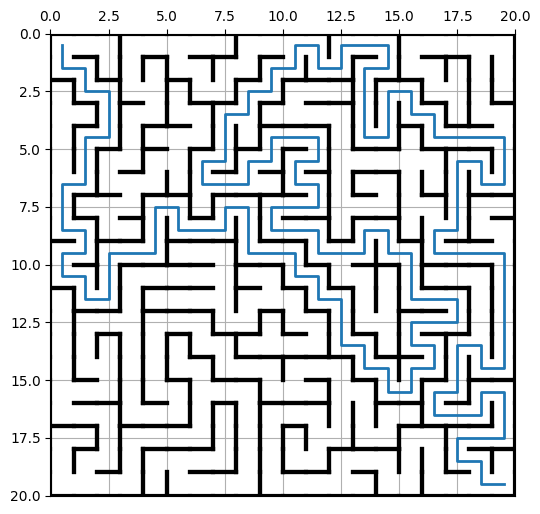

In [23]:
gen = MazeGenerator(grid_size=20)
maze = gen.get_maze_np()
start = (0, 0)
goal  = (19, 19)
path_cells, path_actions = gen.shortest_path(maze, start, goal)
print("Path length:", len(path_cells)-1, "steps")
gen.render_with_path(maze, path_cells)